Problem Definition & Dataset selectioon
Problem Type: Binary Classification

Problem Statement: Predicting whether a film will be commercially successful / profitable (Class 1: Gross Revenue > 2x Budget) or a commercial flop/break-even (Class 0) based on financial, runtime, language, and genre metadata.

Dataset Source: TMDB / IMDb Movies Dataset from Kaggle


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# CONFIGURATION & SEED SETUP


TKH_STUDENT_ID = 2401057
np.random.seed(TKH_STUDENT_ID)

print(f"Notebook initialized successfully.")
print(f"Assigned TKH Student ID Seed: {TKH_STUDENT_ID}")

Notebook initialized successfully.
Assigned TKH Student ID Seed: 2401057


In [2]:

# LOAD DATASET

url = "https://raw.githubusercontent.com/yash91sharma/IMDB-Movie-Dataset-Analysis/master/movie_metadata.csv"

try:
    df_full = pd.read_csv(url)
    print(f"Successfully loaded dataset from online source. Shape: {df_full.shape}")
except Exception as e:
    print(f"Online load failed ({e}). Please ensure 'movie_metadata.csv' is saved locally.")
    df_full = pd.read_csv("movie_metadata.csv")

# Create binary classification target: 1 if gross revenue > 2 * budget (Profitable Hit), else 0
# Note: In this dataset, columns are named 'gross' and 'budget'
df_full['is_profitable'] = ((df_full['gross'] > (df_full['budget'] * 2.0))).astype(int)

# Drop rows where critical financial targets are completely missing/zero to ensure data quality
df_full = df_full[(df_full['budget'] > 0) & (df_full['gross'] > 0)].reset_index(drop=True)

print(f"Dataset rows after filtering zero-budget/zero-gross entries: {len(df_full)}")

# PERSONALISATION RULE: Create a deterministic subsample using the student ID seed
# Taking a robust sample of 3,500 rows (satisfies the >1,000 rows requirement)
SAMPLE_SIZE = min(3500, len(df_full))
df = df_full.sample(n=SAMPLE_SIZE, random_state=TKH_STUDENT_ID).reset_index(drop=True)

print(f"Personalised subsample shape (Seed={TKH_STUDENT_ID}): {df.shape}")
df.head(3)

Successfully loaded dataset from online source. Shape: (5043, 28)
Dataset rows after filtering zero-budget/zero-gross entries: 3891
Personalised subsample shape (Seed=2401057): (3500, 29)


,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,is_profitable
0,Color,Kimberly Peirce,359.0,100.0,108.0,534.0,Judy Greer,17000.0,35266619.0,Drama|Fantasy|Horror,...,English,USA,R,30000000.0,2013.0,2000.0,5.9,2.35,39000,0
1,Color,Sharon Maguire,168.0,97.0,11.0,887.0,Jim Broadbent,14000.0,71500556.0,Comedy|Drama|Romance,...,English,UK,R,26000000.0,2001.0,1000.0,6.7,2.35,0,1
2,Color,Keenen Ivory Wayans,127.0,83.0,322.0,179.0,Veronica Cartwright,1000.0,71277420.0,Comedy,...,English,USA,R,45000000.0,2001.0,422.0,5.2,1.85,0,0


--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 29 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      3498 non-null   str    
 1   director_name              3500 non-null   str    
 2   num_critic_for_reviews     3499 non-null   float64
 3   duration                   3499 non-null   float64
 4   director_facebook_likes    3500 non-null   float64
 5   actor_3_facebook_likes     3491 non-null   float64
 6   actor_2_name               3496 non-null   str    
 7   actor_1_facebook_likes     3497 non-null   float64
 8   gross                      3500 non-null   float64
 9   genres                     3500 non-null   str    
 10  actor_1_name               3497 non-null   str    
 11  movie_title                3500 non-null   str    
 12  num_voted_users            3500 non-null   int64  
 13  cast_total_facebook_likes  3500 non-nu

None


--- Summary Statistics ---


,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes,is_profitable
count,3499.000000,3499.000000,3500.000000,3491.000000,3497.000000,3.500000e+03,3.500000e+03,3500.000000,3494.000000,3500.000000,3.500000e+03,3500.000000,3496.000000,3500.000000,3433.000000,3500.000000,3500.000000
mean,163.082309,109.826808,764.591429,734.903466,7549.197026,5.054843e+07,1.008023e+05,11159.389429,1.386090,322.405143,4.481183e+07,2003.110000,1937.663330,6.460086,2.108025,9129.525714,0.286286
std,124.333931,22.646039,2969.249252,1810.303336,15766.070643,6.836198e+07,1.452676e+05,19164.005406,2.088382,390.896605,2.300418e+08,9.911276,4483.171684,1.047761,0.360314,21305.956928,0.452089
min,1.000000,34.000000,0.000000,0.000000,0.000000,1.620000e+02,5.000000e+00,0.000000,0.000000,1.000000,2.180000e+02,1920.000000,0.000000,1.600000,1.180000,0.000000,0.000000
25%,72.000000,95.000000,10.000000,183.000000,723.000000,7.015300e+06,1.733175e+04,1823.500000,0.000000,103.000000,1.000000e+07,1999.000000,363.000000,5.900000,1.850000,0.000000,0.000000
50%,134.000000,106.000000,58.000000,426.000000,1000.000000,2.799697e+07,5.036300e+04,3859.500000,1.000000,203.000000,2.400000e+07,2005.000000,664.000000,6.600000,2.350000,202.500000,0.000000
75%,221.000000,120.000000,220.250000,685.000000,12000.000000,6.517218e+07,1.242270e+05,15914.500000,2.000000,391.000000,5.000000e+07,2010.000000,971.250000,7.200000,2.350000,11000.000000,1.000000
max,813.000000,330.000000,23000.000000,23000.000000,640000.000000,7.605058e+08,1.689764e+06,656730.000000,43.000000,5060.000000,1.221550e+10,2016.000000,137000.000000,9.300000,16.000000,349000.000000,1.000000



--- Target Class Distribution (%) ---
is_profitable
0    71.371429
1    28.628571
Name: proportion, dtype: float64


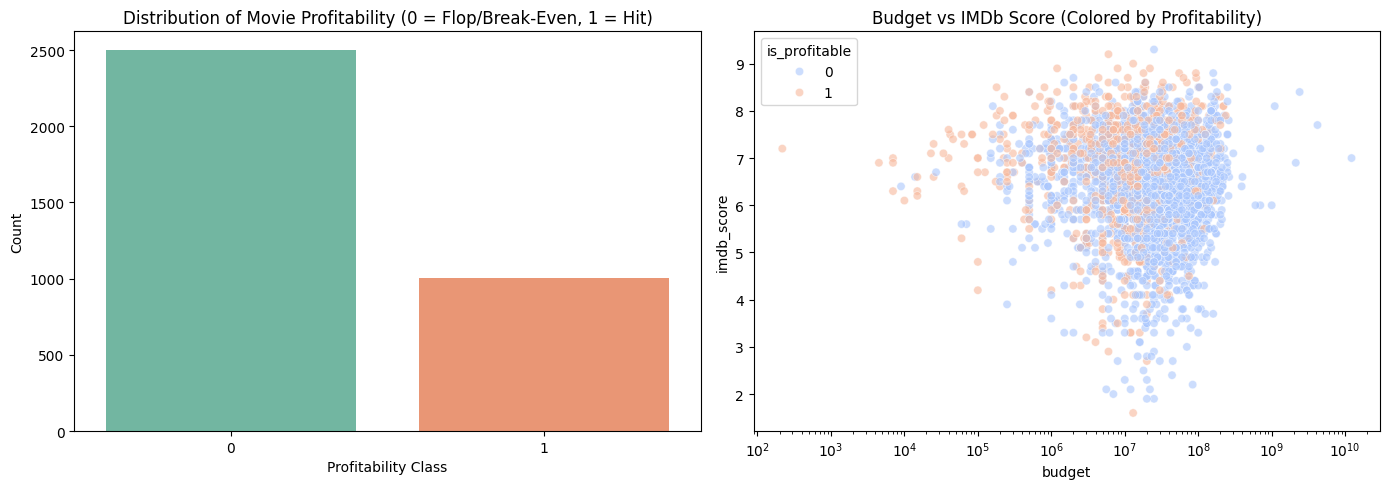

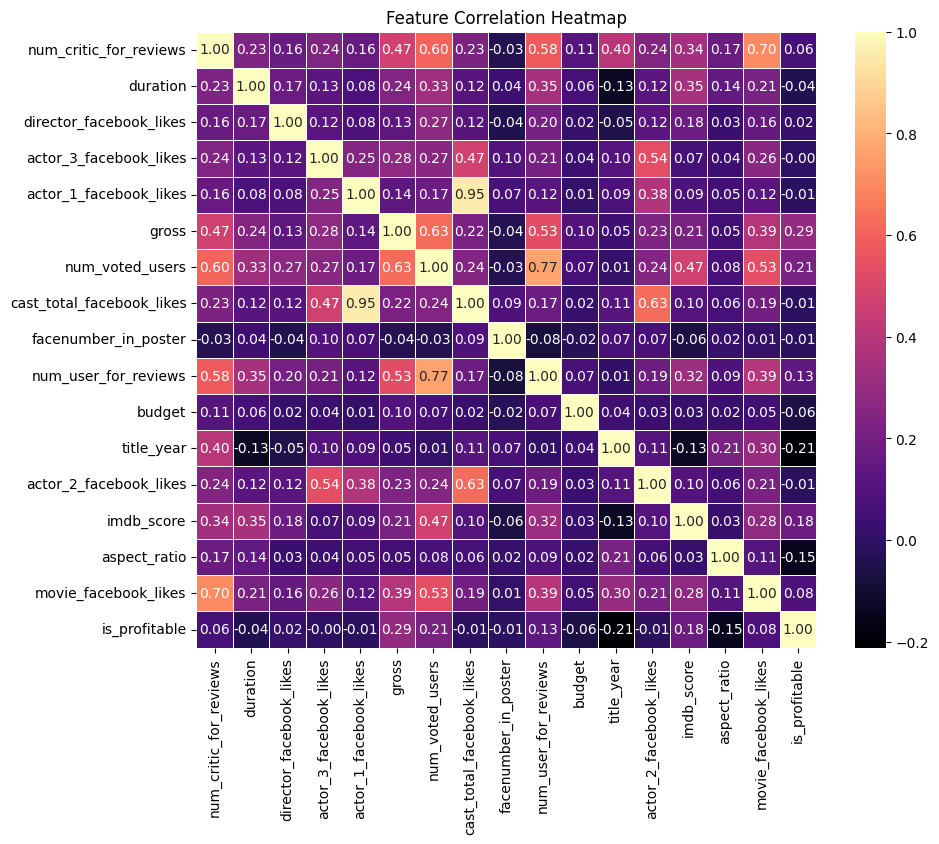

In [3]:

# EXPLORATORY DATA ANALYSIS (EDA)

print("--- Dataset Info ---")
display(df.info())

print("\n--- Summary Statistics ---")
display(df.describe())

# Target Class Distribution Check
print("\n--- Target Class Distribution (%) ---")
print(df['is_profitable'].value_counts(normalize=True) * 100)

# Visualizations
plt.figure(figsize=(14, 5))

# Plot 1: Target Variable Balance
plt.subplot(1, 2, 1)
sns.countplot(x='is_profitable', hue='is_profitable', data=df, palette='Set2', legend=False)
plt.title('Distribution of Movie Profitability (0 = Flop/Break-Even, 1 = Hit)')
plt.xlabel('Profitability Class')
plt.ylabel('Count')

# Plot 2: Budget vs IMDB Score Colored by Profitability
plt.subplot(1, 2, 2)
sns.scatterplot(x='budget', y='imdb_score', hue='is_profitable', data=df, alpha=0.6, palette='coolwarm')
plt.title('Budget vs IMDb Score (Colored by Profitability)')
plt.xscale('log') # Log scale due to extreme budget variations

plt.tight_layout()
plt.show()

# Correlation Matrix Heatmap for Numerical Fields
plt.figure(figsize=(10, 8))
numeric_cols_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols_df.corr(), annot=True, fmt='.2f', cmap='magma', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

In [4]:
# ==========================================
# DATA PRE-PROCESSING PIPELINE
# ==========================================

# 1. Missing Value Treatment
print("Missing values before imputation:\n", df.isnull().sum()[df.isnull().sum() > 0])

# Impute numeric columns with median
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

# Impute categorical/string columns with mode
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# 2. Drop unique text identifiers or target-leaking features (e.g. gross, movie_title)
drop_cols = ['movie_title', 'gross', 'actor_1_name', 'actor_2_name', 'actor_3_name', 'director_name', 'plot_keywords', 'movie_imdb_link']
existing_drops = [col for col in drop_cols if col in df.columns]
df.drop(columns=existing_drops, inplace=True)

# 3. Handle Extreme Outliers & Skewness in Financials via Log Transform & IQR Capping
skewed_cols = ['budget', 'duration', 'num_critic_for_reviews']
for col in skewed_cols:
    if col in df.columns:
        # Log transformation to normalize financial/heavy-tailed metrics
        df[col] = np.log1p(df[col])

        # IQR Outlier Capping
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = np.clip(df[col], lower_bound, upper_bound)

# 4. Categorical Encoding (One-Hot Encoding for text categories like genres, content_rating, language)
categorical_columns = df.select_dtypes(include=['object']).columns
print(f"Categorical columns encoded via One-Hot: {list(categorical_columns)}")
df = pd.get_dummies(df, columns=categorical_columns, drop_first=True)

# 5. Feature Scaling (Standardization for all numerical variables except the binary target)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
features_to_scale = [col for col in df.select_dtypes(include=[np.number]).columns if col != 'is_profitable']

df[features_to_scale] = scaler.fit_transform(df[features_to_scale])

print("\n--- Pre-processing Successfully Completed ---")
print(f"Final pre-processed dataset matrix shape: {df.shape}")
df.head(3)

Missing values before imputation:
 color                      2
num_critic_for_reviews     1
duration                   1
actor_3_facebook_likes     9
actor_2_name               4
actor_1_facebook_likes     3
actor_1_name               3
actor_3_name               9
facenumber_in_poster       6
plot_keywords             28
language                   4
content_rating            47
actor_2_facebook_likes     4
aspect_ratio              67
dtype: int64
Categorical columns encoded via One-Hot: ['color', 'genres', 'language', 'country', 'content_rating']


C:\Users\Amr\AppData\Local\Temp\ipykernel_3264\87920861.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:
C:\Users\Amr\AppData\Local\Temp\ipykernel_3264\87920861.py:37: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migrat


--- Pre-processing Successfully Completed ---
Final pre-processed dataset matrix shape: (3500, 828)


,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,...,content_rating_GP,content_rating_M,content_rating_NC-17,content_rating_Not Rated,content_rating_PG,content_rating_PG-13,content_rating_Passed,content_rating_R,content_rating_Unrated,content_rating_X
0,1.295362,-0.433234,-0.221162,-0.110693,0.600094,0.051221,0.464041,-0.184738,0.124334,0.324331,...,False,False,False,False,False,False,False,True,False,False
1,0.395688,-0.612693,-0.253835,0.084574,0.409717,0.487210,0.304761,0.773872,0.636052,0.217227,...,False,False,False,False,False,False,False,True,False,False
2,0.065102,-1.530135,-0.149080,-0.307066,-0.415249,0.129350,-0.496543,2.691092,0.577204,0.627800,...,False,False,False,False,False,False,False,True,False,False


## Milestone 2: Model Implementation & Evaluation
### Deliverable Focus: Unsupervised Feature Engineering, Supervised Model Training, Cross-Validation, Evaluation Metrics & Hyperparameter Tuning

In this section, we complete all **Milestone 2** tasks on our personalised subsample (`TKH_STUDENT_ID = 2401057`, $N = 3,500$):
1. **Unsupervised Learning for Feature Engineering & Dimensionality Reduction**: Apply **K-Means Clustering** (with Silhouette score optimization) to discover latent movie profile clusters and append cluster membership as an engineered feature, alongside **Principal Component Analysis (PCA)** to inspect variance structure.
2. **Train Multiple Supervised Learning Algorithms**: Train and compare **4 distinct supervised classification models** (*Logistic Regression*, *Random Forest Classifier*, *Gradient Boosting Classifier*, and *Support Vector Machine (SVC)*) using an 80/20 stratified train-test split.
3. **Cross-Validation & Comprehensive Evaluation**: Evaluate all models via **5-Fold Stratified Cross-Validation**, Confusion Matrices, ROC-AUC curves, Precision, Recall, F1-Score, and Accuracy.
4. **Hyperparameter Tuning**: Optimize the top-performing models using `GridSearchCV` and `RandomizedSearchCV`, followed by a comparative performance analysis before and after tuning.

Training set shape: (2800, 827) | Class 1 ratio: 0.286
Testing set shape:  (700, 827)  | Class 1 ratio: 0.286



K-Means Silhouette Scores by k: {2: 0.3203, 3: 0.2203, 4: 0.2194, 5: 0.1314, 6: 0.1037}
Optimal number of movie clusters selected: k = 2 (Silhouette = 0.3203)
Top 5 PCA Components Explained Variance Ratio: [0.2421 0.1242 0.0903 0.0625 0.0612]
Cumulative Variance Explained by Top 5 PCs: 58.03%
Feature matrix shape after Unsupervised Feature Engineering: Train=(2800, 832), Test=(700, 832)


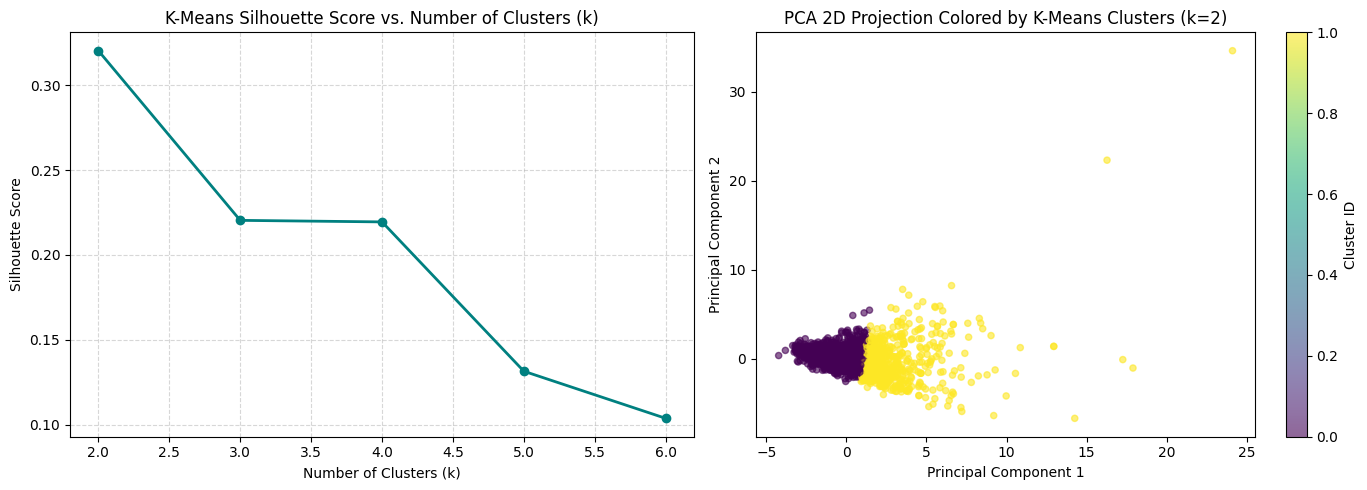

In [5]:
# ==========================================
# 1. TRAIN-TEST SPLIT & UNSUPERVISED FEATURE ENGINEERING (K-MEANS + PCA)
# ==========================================
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, silhouette_score
)
import warnings
warnings.filterwarnings('ignore')

# Separate features (X) and binary target (y)
X = df.drop(columns=['is_profitable']).copy()
y = df['is_profitable'].copy()

# Convert boolean dummy columns to numeric (float) for matrix operations
X = X.astype(float)

# Deterministic 80/20 Stratified Train-Test Split seeded with TKH_STUDENT_ID
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=TKH_STUDENT_ID
)

print(f"Training set shape: {X_train.shape} | Class 1 ratio: {y_train.mean():.3f}")
print(f"Testing set shape:  {X_test.shape}  | Class 1 ratio: {y_test.mean():.3f}")

# --- Unsupervised Method 1: K-Means Clustering for Feature Engineering ---
# Select core continuous/standardized numerical features to identify latent movie archetypes
core_num_cols = [
    'num_critic_for_reviews', 'duration', 'director_facebook_likes',
    'actor_3_facebook_likes', 'actor_1_facebook_likes', 'num_voted_users',
    'cast_total_facebook_likes', 'facenumber_in_poster', 'num_user_for_reviews',
    'budget', 'title_year', 'actor_2_facebook_likes', 'imdb_score',
    'aspect_ratio', 'movie_facebook_likes'
]

# Evaluate k from 2 to 6 using Silhouette Score on X_train
sil_scores = {}
inertias = {}
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=TKH_STUDENT_ID, n_init=10)
    labels = km.fit_predict(X_train[core_num_cols])
    sil_scores[k] = silhouette_score(X_train[core_num_cols], labels)
    inertias[k] = km.inertia_

best_k = max(sil_scores, key=sil_scores.get)
print(f"\nK-Means Silhouette Scores by k: { {k: round(v, 4) for k, v in sil_scores.items()} }")
print(f"Optimal number of movie clusters selected: k = {best_k} (Silhouette = {sil_scores[best_k]:.4f})")

# Fit optimal K-Means on training data and transform both train and test sets (prevents data leakage)
kmeans_final = KMeans(n_clusters=best_k, random_state=TKH_STUDENT_ID, n_init=10)
train_clusters = kmeans_final.fit_predict(X_train[core_num_cols])
test_clusters = kmeans_final.predict(X_test[core_num_cols])

# --- Unsupervised Method 2: Principal Component Analysis (PCA) ---
# Extract top 5 orthogonal principal components from the high-dimensional feature space
pca = PCA(n_components=5, random_state=TKH_STUDENT_ID)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(f"Top 5 PCA Components Explained Variance Ratio: {np.round(pca.explained_variance_ratio_, 4)}")
print(f"Cumulative Variance Explained by Top 5 PCs: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# Append engineered unsupervised features (Cluster One-Hot + Top 3 PCA components) to X_train and X_test
for c_id in range(best_k):
    X_train[f'kmeans_cluster_{c_id}'] = (train_clusters == c_id).astype(float)
    X_test[f'kmeans_cluster_{c_id}'] = (test_clusters == c_id).astype(float)

for pc_idx in range(3):
    X_train[f'pca_comp_{pc_idx+1}'] = X_train_pca[:, pc_idx]
    X_test[f'pca_comp_{pc_idx+1}'] = X_test_pca[:, pc_idx]

print(f"Feature matrix shape after Unsupervised Feature Engineering: Train={X_train.shape}, Test={X_test.shape}")

# Visualize K-Means Elbow/Silhouette & PCA 2D Projection
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(sil_scores.keys()), list(sil_scores.values()), marker='o', color='teal', linewidth=2)
axes[0].set_title('K-Means Silhouette Score vs. Number of Clusters (k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Silhouette Score')
axes[0].grid(True, linestyle='--', alpha=0.5)

scatter = axes[1].scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=train_clusters, cmap='viridis', alpha=0.6, s=20)
axes[1].set_title(f'PCA 2D Projection Colored by K-Means Clusters (k={best_k})')
axes[1].set_xlabel('Principal Component 1')
axes[1].set_ylabel('Principal Component 2')
plt.colorbar(scatter, ax=axes[1], label='Cluster ID')
plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# 2. SUPERVISED LEARNING MODELS & 5-FOLD STRATIFIED CROSS-VALIDATION
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC

# Initialize 4 diverse supervised classification algorithms seeded with TKH_STUDENT_ID
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=TKH_STUDENT_ID),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=TKH_STUDENT_ID, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=TKH_STUDENT_ID),
    'Support Vector Machine (SVC)': SVC(probability=True, random_state=TKH_STUDENT_ID)
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=TKH_STUDENT_ID)

baseline_results = []
trained_models = {}

print("Training baseline supervised models and running 5-Fold Stratified Cross-Validation...\n")
for name, model in models.items():
    # 5-Fold Cross-Validation on Training Set
    cv_acc = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='accuracy', n_jobs=-1)
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='f1', n_jobs=-1)
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1)
    
    # Fit on full training set and evaluate on hold-out test set
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    baseline_results.append({
        'Model': name,
        'CV Accuracy (Mean ± Std)': f"{cv_acc.mean():.4f} ± {cv_acc.std():.4f}",
        'CV F1-Score (Mean)': round(cv_f1.mean(), 4),
        'CV ROC-AUC (Mean)': round(cv_auc.mean(), 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred), 4),
        'Test Recall': round(recall_score(y_test, y_pred), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

results_df = pd.DataFrame(baseline_results)
print("--- Baseline Supervised Models Evaluation Summary ---")
display(results_df)

Training baseline supervised models and running 5-Fold Stratified Cross-Validation...



--- Baseline Supervised Models Evaluation Summary ---


,Model,CV Accuracy (Mean ± Std),CV F1-Score (Mean),CV ROC-AUC (Mean),Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
0,Logistic Regression,0.7943 ± 0.0180,0.5681,0.8296,0.7886,0.7167,0.430,0.5375,0.8042
1,Random Forest,0.7950 ± 0.0163,0.5121,0.8425,0.7900,0.8193,0.340,0.4806,0.8193
2,Gradient Boosting,0.8075 ± 0.0088,0.5953,0.8591,0.7900,0.7054,0.455,0.5532,0.8517
3,Support Vector Machine (SVC),0.7946 ± 0.0098,0.5372,0.8660,0.7900,0.7624,0.385,0.5116,0.8471


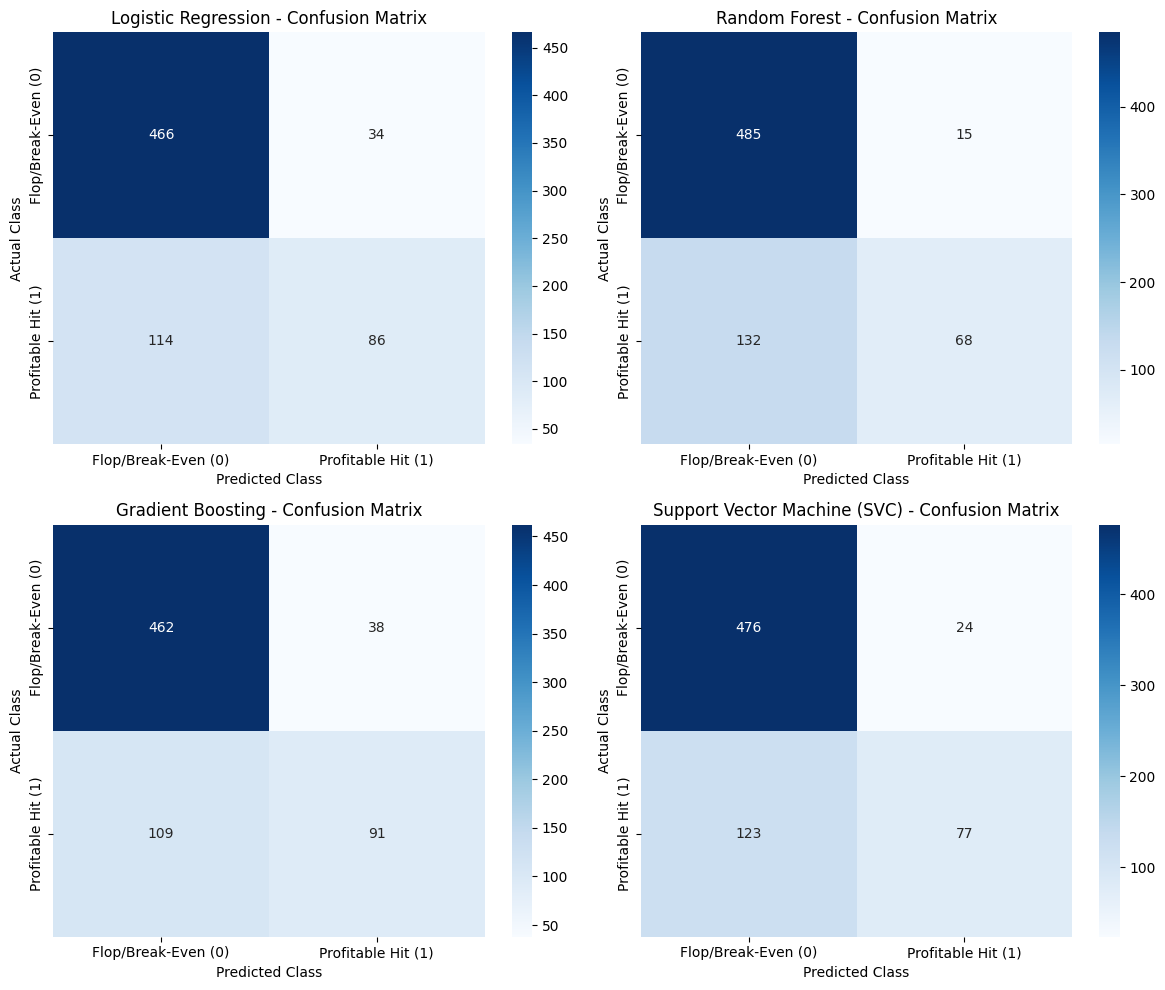

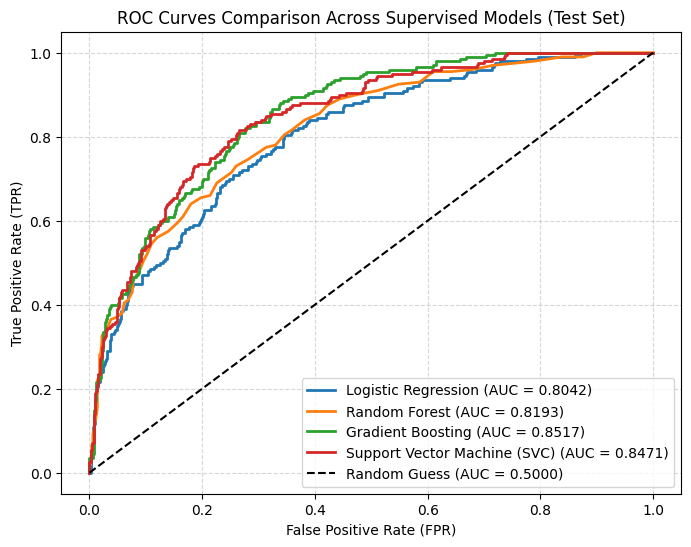

In [7]:
# ==========================================
# 3. CONFUSION MATRICES & ROC CURVES FOR BASELINE MODELS
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, (name, model) in enumerate(trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
        xticklabels=['Flop/Break-Even (0)', 'Profitable Hit (1)'],
        yticklabels=['Flop/Break-Even (0)', 'Profitable Hit (1)']
    )
    axes[idx].set_title(f'{name} - Confusion Matrix')
    axes[idx].set_xlabel('Predicted Class')
    axes[idx].set_ylabel('Actual Class')

plt.tight_layout()
plt.show()

# Plot Comparative ROC Curves
plt.figure(figsize=(8, 6))
for name, model in trained_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')
plt.title('ROC Curves Comparison Across Supervised Models (Test Set)')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
# ==========================================
# 4. HYPERPARAMETER TUNING (GRID SEARCH & RANDOMIZED SEARCH)
# ==========================================
print("Starting Hyperparameter Optimization via GridSearchCV and RandomizedSearchCV...\n")

# 4.1 Tune Gradient Boosting Classifier via GridSearchCV
gb_param_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1, 0.15],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}
gb_grid = GridSearchCV(
    GradientBoostingClassifier(random_state=TKH_STUDENT_ID),
    param_grid=gb_param_grid,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
print(f"Best Gradient Boosting Parameters (GridSearchCV): {gb_grid.best_params_}")
print(f"Best Gradient Boosting 5-Fold CV F1-Score: {gb_grid.best_score_:.4f}\n")

# 4.2 Tune Random Forest Classifier via RandomizedSearchCV
rf_param_dist = {
    'n_estimators': [150, 250, 350],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced', 'balanced_subsample']
}
rf_random = RandomizedSearchCV(
    RandomForestClassifier(random_state=TKH_STUDENT_ID, n_jobs=-1),
    param_distributions=rf_param_dist,
    n_iter=15,
    cv=cv_strategy,
    scoring='f1',
    random_state=TKH_STUDENT_ID,
    n_jobs=-1
)
rf_random.fit(X_train, y_train)
best_rf = rf_random.best_estimator_
print(f"Best Random Forest Parameters (RandomizedSearchCV): {rf_random.best_params_}")
print(f"Best Random Forest 5-Fold CV F1-Score: {rf_random.best_score_:.4f}\n")

# 4.3 Tune Logistic Regression via GridSearchCV
lr_param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'class_weight': [None, 'balanced'],
    'solver': ['lbfgs', 'liblinear']
}
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=TKH_STUDENT_ID),
    param_grid=lr_param_grid,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1
)
lr_grid.fit(X_train, y_train)
best_lr = lr_grid.best_estimator_
print(f"Best Logistic Regression Parameters (GridSearchCV): {lr_grid.best_params_}")
print(f"Best Logistic Regression 5-Fold CV F1-Score: {lr_grid.best_score_:.4f}")

Starting Hyperparameter Optimization via GridSearchCV and RandomizedSearchCV...



Best Gradient Boosting Parameters (GridSearchCV): {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'subsample': 0.8}
Best Gradient Boosting 5-Fold CV F1-Score: 0.6513



Best Random Forest Parameters (RandomizedSearchCV): {'n_estimators': 350, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 30, 'class_weight': 'balanced'}
Best Random Forest 5-Fold CV F1-Score: 0.6106



Best Logistic Regression Parameters (GridSearchCV): {'C': 0.1, 'class_weight': 'balanced', 'solver': 'lbfgs'}
Best Logistic Regression 5-Fold CV F1-Score: 0.6368


--- Tuned Models Performance Summary (Test Set & 5-Fold CV) ---


,Model,CV F1-Score (Mean),CV ROC-AUC (Mean),Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
0,Tuned Gradient Boosting,0.6513,0.8770,0.8029,0.7067,0.530,0.6057,0.8552
1,Tuned Random Forest,0.6106,0.8299,0.7757,0.6201,0.555,0.5858,0.8202
2,Tuned Logistic Regression,0.6368,0.8288,0.7471,0.5466,0.675,0.6040,0.7984



--- Detailed Classification Report: Tuned Gradient Boosting ---
                     precision    recall  f1-score   support

Flop/Break-Even (0)       0.83      0.91      0.87       500
 Profitable Hit (1)       0.71      0.53      0.61       200

           accuracy                           0.80       700
          macro avg       0.77      0.72      0.74       700
       weighted avg       0.79      0.80      0.79       700



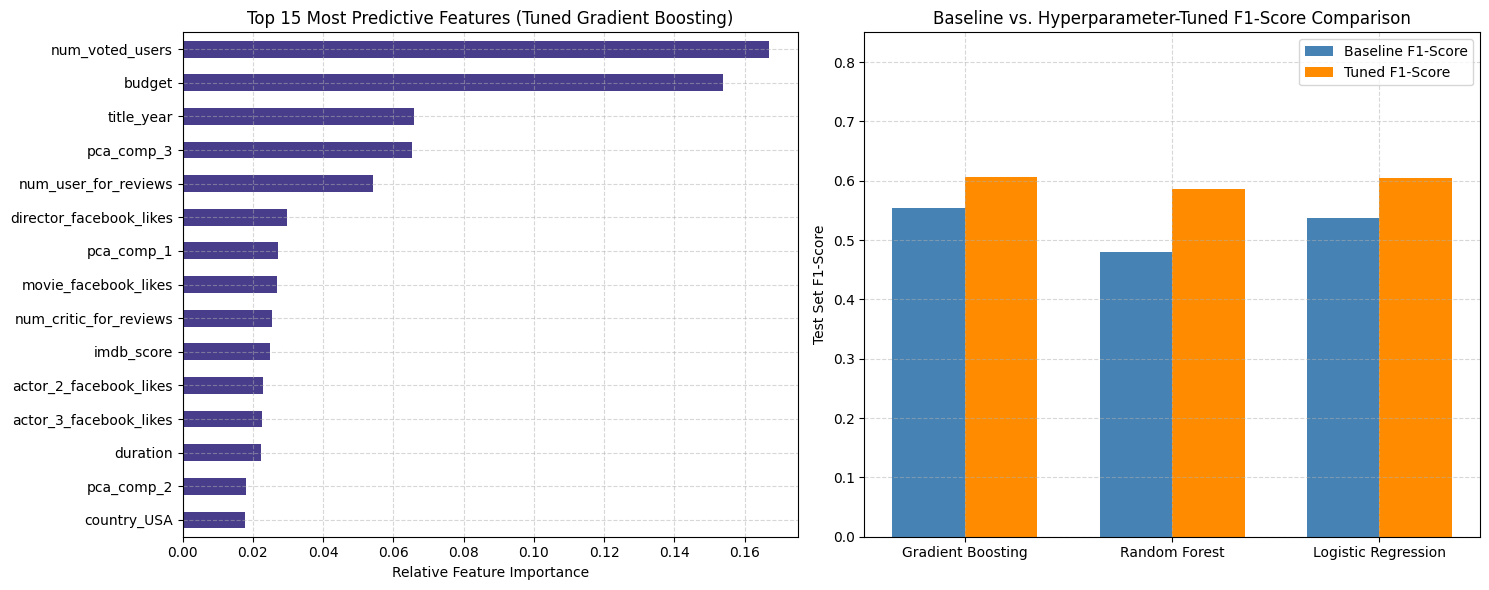

In [9]:
# ==========================================
# 5. POST-TUNING EVALUATION & COMPARATIVE ANALYSIS
# ==========================================
tuned_models = {
    'Tuned Gradient Boosting': best_gb,
    'Tuned Random Forest': best_rf,
    'Tuned Logistic Regression': best_lr
}

tuned_results = []
for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='f1', n_jobs=-1).mean()
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv_strategy, scoring='roc_auc', n_jobs=-1).mean()
    
    tuned_results.append({
        'Model': name,
        'CV F1-Score (Mean)': round(cv_f1, 4),
        'CV ROC-AUC (Mean)': round(cv_auc, 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred), 4),
        'Test Recall': round(recall_score(y_test, y_pred), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_prob), 4)
    })

tuned_df = pd.DataFrame(tuned_results)
print("--- Tuned Models Performance Summary (Test Set & 5-Fold CV) ---")
display(tuned_df)

# Detailed Classification Report for Best Tuned Model
best_overall_name = tuned_df.sort_values(by='Test F1-Score', ascending=False).iloc[0]['Model']
best_overall_model = tuned_models[best_overall_name]
print(f"\n--- Detailed Classification Report: {best_overall_name} ---")
print(classification_report(y_test, best_overall_model.predict(X_test), target_names=['Flop/Break-Even (0)', 'Profitable Hit (1)']))

# Feature Importance Plot from Tuned Gradient Boosting
importances = pd.Series(best_gb.feature_importances_, index=X_train.columns)
top_15_features = importances.nlargest(15).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_15_features.plot(kind='barh', color='darkslateblue', ax=axes[0])
axes[0].set_title('Top 15 Most Predictive Features (Tuned Gradient Boosting)')
axes[0].set_xlabel('Relative Feature Importance')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Bar chart comparing Baseline vs Tuned Test F1-Scores
comp_data = pd.DataFrame({
    'Algorithm': ['Gradient Boosting', 'Random Forest', 'Logistic Regression'],
    'Baseline F1': [
        results_df.loc[results_df['Model']=='Gradient Boosting', 'Test F1-Score'].values[0],
        results_df.loc[results_df['Model']=='Random Forest', 'Test F1-Score'].values[0],
        results_df.loc[results_df['Model']=='Logistic Regression', 'Test F1-Score'].values[0]
    ],
    'Tuned F1': [
        tuned_df.loc[tuned_df['Model']=='Tuned Gradient Boosting', 'Test F1-Score'].values[0],
        tuned_df.loc[tuned_df['Model']=='Tuned Random Forest', 'Test F1-Score'].values[0],
        tuned_df.loc[tuned_df['Model']=='Tuned Logistic Regression', 'Test F1-Score'].values[0]
    ]
})
x_pos = np.arange(len(comp_data['Algorithm']))
width = 0.35
axes[1].bar(x_pos - width/2, comp_data['Baseline F1'], width, label='Baseline F1-Score', color='steelblue')
axes[1].bar(x_pos + width/2, comp_data['Tuned F1'], width, label='Tuned F1-Score', color='darkorange')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(comp_data['Algorithm'])
axes[1].set_ylim(0, 0.85)
axes[1].set_ylabel('Test Set F1-Score')
axes[1].set_title('Baseline vs. Hyperparameter-Tuned F1-Score Comparison')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()